# Data loading with SOBER

SOBER (Spatial Omics Biomarker Encoder) takes a center cell and its spatial neighbors as input. This tutorial follows three complete, real multiplexed imaging regions from CSV tables to model-ready neighborhoods.

You will inspect the tables, check cell alignment, normalize marker intensities, and visualize a spatial neighborhood. Basic Python and pandas are sufficient; no GPU or checkpoint is needed.

From the repository root, install the tutorial dependencies and open this notebook:

```bash
python -m pip install -r requirements-tutorials.txt
python -m jupyterlab tutorials/data_loading.ipynb
```

In [1]:
from pathlib import Path
from contextlib import redirect_stdout
import io
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "tutorials":
    ROOT = ROOT.parent
if not (ROOT / "sober").is_dir():
    raise FileNotFoundError("Open the notebook from the SOBER root or tutorials folder.")
sys.path.insert(0, str(ROOT))
DATA_ROOT = ROOT / "examples" / "data"

from sober.config import Config
from sober.data_loader import SpatialBiomarkerDataset
from sober.spatial_sampler import SpatialSampler

%matplotlib inline
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})

## The example regions

The examples include one **internal training** region from UPMC-HNC (`s240`, CODEX; 1,670 cells) and two **external** IMC regions from Damond (pancreas) and Meyer (breast cancer), each with 1,500 cells. All cells in each supplied region are retained.

The UPMC-HNC region is listed in the saved training partition, not internal validation. Its labels use the training-selected `95-5-4` annotation version. The two external regions are absent from that split. These are data-loading examples, not a benchmark. See [the example data notes](../examples/data/README.md) for sources, preparation, and licenses.


In [2]:
manifest = json.loads((DATA_ROOT / "manifest.json").read_text())
examples = manifest["examples"]
pd.DataFrame(examples)[["label", "scope", "platform", "cells", "raw_markers", "author_label_categories"]]

,label,scope,platform,cells,raw_markers,author_label_categories
0,Damond 2019 pancreas,External,IMC,1500,35,14
1,Meyer 2025 breast cancer,External,IMC,1500,36,14
2,UPMC-HNC (s240),Internal training,PhenoCycler (CODEX),1670,41,14


## Inspect the input tables

SOBER expects `study/region/` folders containing `cell_data.csv` (`cell_id,x,y`), `expression.csv` (`cell_id` followed by marker columns), and optionally `cell_type.csv` (`cell_id,cell_type`).

We start with the breast cancer region. Set `example = examples[0]` to inspect the pancreas region instead.

In [3]:
example = next(item for item in examples if item["study"] == "meyer2025stratification")
region_path = DATA_ROOT / example["folder"]
positions = pd.read_csv(region_path / "cell_data.csv", dtype={"cell_id": str})
expression = pd.read_csv(region_path / "expression.csv", dtype={"cell_id": str})
annotations = pd.read_csv(region_path / "cell_type.csv", dtype={"cell_id": str})

display(pd.DataFrame({
    "table": ["cell_data.csv", "expression.csv", "cell_type.csv"],
    "rows": [len(positions), len(expression), len(annotations)],
    "columns": [len(positions.columns), len(expression.columns), len(annotations.columns)],
}))
display(expression.iloc[:5, :6])

,table,rows,columns
0,cell_data.csv,1500,3
1,expression.csv,1500,37
2,cell_type.csv,1500,2


,cell_id,trime_H3,CK5,Fibronectin,HLADR,CK8_18
0,ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_1,0.989762,0.171857,1.794149,0.445587,0.112166
1,ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_2,0.728976,0.150714,21.738286,0.385951,0.204768
2,ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_3,1.853333,0.338167,9.973277,21.295975,0.382442
3,ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_4,0.577225,0.079755,6.946547,15.718174,0.961103
4,ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_5,1.134989,0.177057,5.258454,1.839712,0.217135


## Match cells by ID

Row order can differ between tables. Match rows using `cell_id` before combining coordinates, intensities, or annotations. These examples have complete annotations; the loader also accepts partially annotated regions.

In [4]:
for table in (positions, expression, annotations):
    assert table["cell_id"].notna().all()
    assert table["cell_id"].is_unique
assert set(positions["cell_id"]) == set(expression["cell_id"])
assert set(positions["cell_id"]) == set(annotations["cell_id"])

cell_ids = positions["cell_id"]
raw = expression.set_index("cell_id").loc[cell_ids]
labels = annotations.set_index("cell_id").loc[cell_ids, "cell_type"]
xy = positions[["x", "y"]].to_numpy()
assert np.isfinite(xy).all()
assert np.isfinite(raw.to_numpy()).all() and (raw.to_numpy() >= 0).all()

preview = positions.set_index("cell_id").join(labels).join(raw.iloc[:, :3])
display(preview.head())

,x,y,cell_type,trime_H3,CK5,Fibronectin
cell_id,,,,,,
ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_1,427.238095,1.714286,CD4_T_cell,0.989762,0.171857,1.794149
ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_2,820.523810,42.857143,Stromal,0.728976,0.150714,21.738286
ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_3,790.185185,54.037037,Monocyte,1.853333,0.338167,9.973277
ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_4,694.196078,66.627451,tumor_7,0.577225,0.079755,6.946547
ZTMA249.1_ZTMA249_ID_48_AX8Y6_30_5,821.632184,66.505747,tumor_6,1.134989,0.177057,5.258454


## Load and normalize with SOBER

The loader resolves marker aliases, aligns cells, and normalizes each marker separately within each region: adaptive arcsinh transformation, division by the sample standard deviation, then clipping to `[0, 5]`. It does **not** subtract the marker mean. Pass raw intensities to the loader; do not normalize them beforehand.

Source annotation strings are retained for inspection. They are not automatically equivalent to the coarse labels used for supervised training.

In [5]:
config = Config(device="cpu")
with redirect_stdout(io.StringIO()):
    dataset = SpatialBiomarkerDataset(DATA_ROOT, config)

summary = []
for item in dataset.regions:
    summary.append({
        "study": item["study_name"],
        "cells": item["num_cells"],
        "retained markers": len(item["biomarkers"]),
        "minimum intensity": item["intensities"].min(),
        "maximum intensity": item["intensities"].max(),
    })
display(pd.DataFrame(summary).round(3))

region = next(item for item in dataset.regions
              if item["study_name"] == example["study"]
              and item["region_name"] == example["region"])
aliases = config.biomarker_aliases()
marker_names = pd.DataFrame({
    "input name": raw.columns,
    "canonical name": [aliases.get(name, name) for name in raw.columns],
})
display(marker_names[marker_names["input name"] != marker_names["canonical name"]])

,study,cells,retained markers,minimum intensity,maximum intensity
0,damond2019map,1500,35,0.000,5.0
1,meyer2025stratification,1500,36,0.000,5.0
2,s240,1670,41,0.046,5.0


,input name,canonical name
1,CK5,Keratin5
3,HLADR,HLA-DR
4,CK8_18,Keratin8/18
7,CK14,Keratin14
8,SMA,aSMA
12,CD3,CD3e
16,ER,ERa
17,PR,PGR
24,CD8a,CD8
33,CK7,Keratin7


A canonical name of `EMPTY` means that the marker is excluded by the alias table. Other markers can be loaded even if they are absent from a particular pretrained model's vocabulary. Check vocabulary overlap when loading that model; the data loader alone does not establish compatibility.

## View the tissue coordinates

The external examples use the local conversion convention of **0.5 micrometres per model unit**; the Meyer acquisition scale has not been independently verified. UPMC-HNC retains its native coordinates and is plotted in source units because its physical calibration has not been verified for this export. The SOBER loader does not convert units. See [coordinate metadata](../examples/data/manifest.json).

Colors show normalized CD3e intensity. Each region is normalized independently; the colors do not calibrate absolute expression across studies.


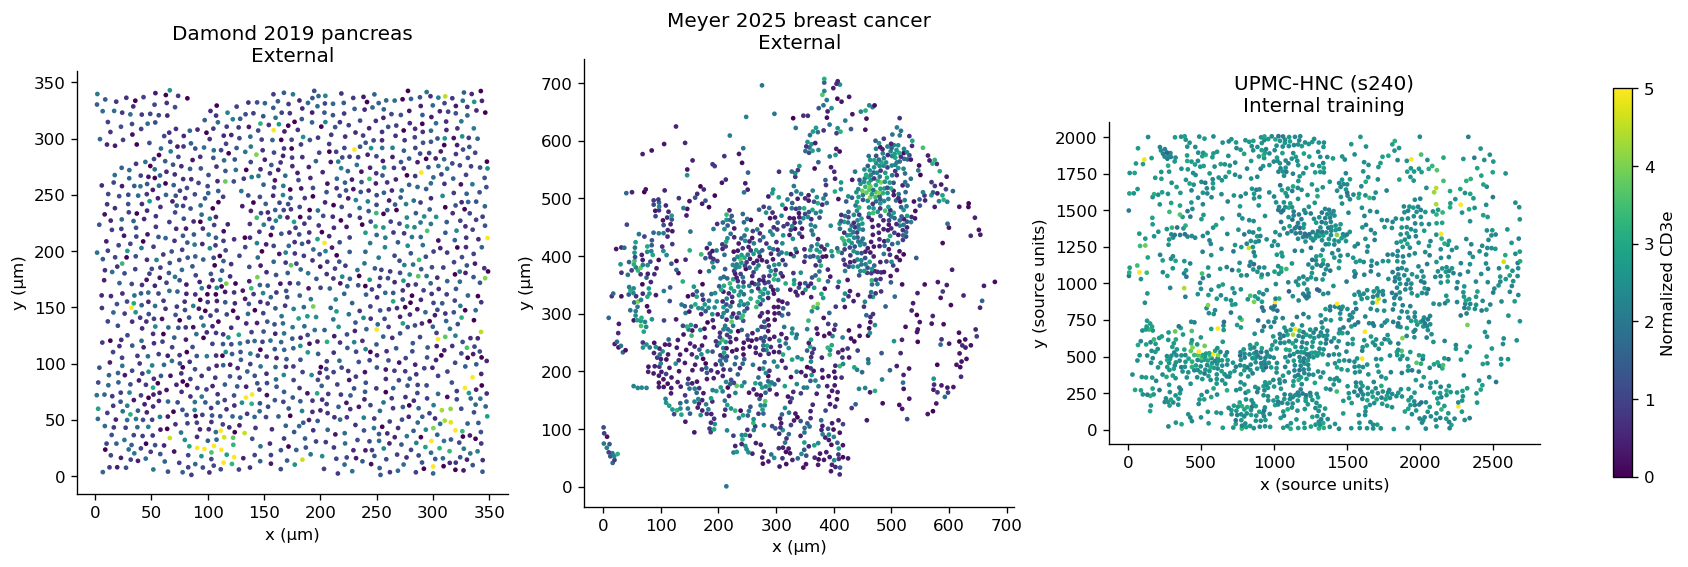

In [6]:
marker = "CD3e"
fig, axes = plt.subplots(1, len(dataset.regions), figsize=(14, 4.5), layout="constrained")
for ax, item in zip(axes, dataset.regions):
    info = next(row for row in examples if row["study"] == item["study_name"])
    scale = info["microns_per_model_unit"]
    coords = item["coordinates"] * (scale if scale is not None else 1)
    unit = "µm" if scale is not None else "source units"
    marker_idx = item["biomarkers"].index(marker)
    points = ax.scatter(coords[:, 0], coords[:, 1],
                        c=item["intensities"][:, marker_idx], s=8,
                        cmap="viridis", vmin=0, vmax=5, linewidths=0)
    ax.set(title=f'{info["label"]}\n{info["scope"]}', xlabel=f"x ({unit})", ylabel=f"y ({unit})")
    ax.set_aspect("equal")
fig.colorbar(points, ax=axes, label=f"Normalized {marker}", shrink=0.8)
plt.show()


## Construct a center-cell neighborhood

For the Meyer breast cancer region, center row 540 illustrates a neighborhood whose 100th nearest neighbor lies near the radius limit. The sampler selects at most **100 nearest neighbors** within **300 coordinate units**. Under this example's conversion convention, the radius is 150 micrometres. The center is the first token, with coordinates relative to it.

The same numeric radius is not necessarily the same physical distance in another dataset. Confirm coordinate calibration before comparing physical neighborhoods.


In [7]:
coordinates = region["coordinates"]
center_idx = 540
sampler = SpatialSampler(config)
neighborhood = sampler.sample_region_at(region, center_idx=center_idx)

assert neighborhood["cell_ids"][0] == region["cell_ids"][center_idx]
assert np.allclose(neighborhood["coordinates"][0], [0, 0])
distances = np.linalg.norm(neighborhood["coordinates"][1:], axis=1)
assert len(distances) <= config.max_neighbors
assert (distances <= config.neighbor_distance_threshold).all()

display(pd.DataFrame({
    "field": ["coordinates", "intensities", "biomarkers", "neighbors"],
    "shape or count": [str(neighborhood["coordinates"].shape),
                       str(neighborhood["intensities"].shape),
                       len(neighborhood["biomarkers"]), len(distances)],
}))

all_distances = np.linalg.norm(coordinates - coordinates[center_idx], axis=1)
within_radius = all_distances <= config.neighbor_distance_threshold
within_radius[center_idx] = False
n_within_radius = int(within_radius.sum())
scale = example["microns_per_model_unit"]
unit = "µm" if scale is not None else "source units"
scale = scale if scale is not None else 1
farthest = distances.max(initial=0) * scale
print(f"Available within {config.neighbor_distance_threshold * scale:g} {unit}: {n_within_radius} neighbors")
print(f"Selected: {len(distances)} nearest neighbors; farthest selected: {farthest:.1f} {unit}")

,field,shape or count
0,coordinates,"(101, 2)"
1,intensities,"(101, 36)"
2,biomarkers,36
3,neighbors,100


Available within 150 µm: 105 neighbors
Selected: 100 nearest neighbors; farthest selected: 146.0 µm


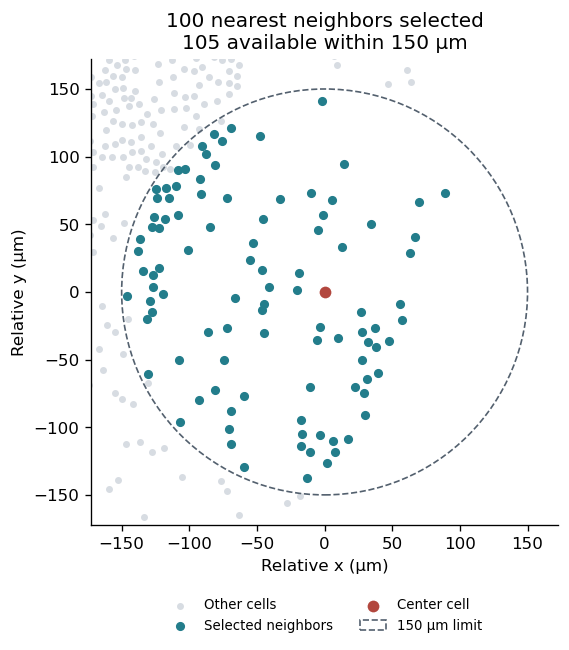

In [8]:
relative = (coordinates - coordinates[center_idx]) * scale
neighbors = neighborhood["coordinates"][1:] * scale
radius = config.neighbor_distance_threshold * scale

fig, ax = plt.subplots(figsize=(5.5, 5.3), layout="constrained")
ax.scatter(relative[:, 0], relative[:, 1], s=10,
           color="#d7dce2", label="Other cells")
ax.scatter(neighbors[:, 0], neighbors[:, 1], s=20,
           color="#237d8b", label="Selected neighbors")
ax.scatter([0], [0], s=65, facecolor="#b2473e", edgecolor="white",
           linewidth=1, zorder=4, label="Center cell")
ax.add_patch(Circle((0, 0), radius, fill=False, color="#53606e",
                    linestyle="--", linewidth=1, label=f"{radius:g} {unit} limit"))
ax.set(xlim=(-radius * 1.15, radius * 1.15),
       ylim=(-radius * 1.15, radius * 1.15),
       xlabel=f"Relative x ({unit})", ylabel=f"Relative y ({unit})",
       title=(f"{len(distances)} nearest neighbors selected\n"
              f"{n_within_radius} available within {radius:g} {unit}"))
ax.set_aspect("equal")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13),
          ncol=2, frameon=False, fontsize=8)
plt.show()

The dashed circle shows the maximum allowed distance. Teal cells are the nearest neighbors actually selected; gray cells inside the circle are omitted once the 100-neighbor cap is reached. Thus, the radius is an upper distance limit, and the selected neighborhood can occupy a much smaller area.

The intensity array is aligned to `neighborhood["biomarkers"]`; its first row belongs to the center. Masking happens later in the model, not during data loading.

## Try a different center

Change `other_center_idx` below and check that the new center still occupies the first row at `(0, 0)`. To inspect the internal example, set `example = next(item for item in examples if item["study"] == "s240")` in the input-table cell and rerun the following cells. Its distances are shown in source units.

In [9]:
other_center_idx = region["num_cells"] // 3
other = sampler.sample_region_at(region, center_idx=other_center_idx)
assert other["original_indices"][0] == other_center_idx
assert np.allclose(other["coordinates"][0], [0, 0])
print(f"Center row: {other_center_idx}; neighbors: {len(other['cell_ids']) - 1}")

Center row: 500; neighbors: 69
